# Road Accident Risk Prediction - Modeling

This notebook reuses the train-validation split established in data_split.py and develops two supervised learning models:

1. Multiple Linear Regression
2. Logistic Regression

The regression model estimates continuous accident risk, while the
classification model identifies high-risk observations for safety
prioritization.

## Stage 1: Modeling Setup and Data Split Verification

This stage prepares the modeling notebook and verifies the existing
train-validation split created during P1 before model development begins.

In [72]:
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

sys.path.append("../src")

from data_split import load_and_split_data

X_train, X_val, y_train, y_val = load_and_split_data()

In [73]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

FIGURE_DIR = PROJECT_ROOT / "reports" / "figures"
TABLE_DIR = PROJECT_ROOT / "reports" / "tables"

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

print("Figure folder:", FIGURE_DIR)
print("Table folder:", TABLE_DIR)

Figure folder: c:\Users\ngoho\OneDrive\Desktop\UOP\Fall 2026\MSBA 265\road-accident-risk-prediction\reports\figures
Table folder: c:\Users\ngoho\OneDrive\Desktop\UOP\Fall 2026\MSBA 265\road-accident-risk-prediction\reports\tables


In [74]:
print("Training mean:", y_train.mean())
print("Validation mean:", y_val.mean())

print("Training median:", y_train.median())
print("Validation median:", y_val.median())

Training mean: 0.3526053167166824
Validation mean: 0.35146575117574913
Training median: 0.34
Validation median: 0.34


In [75]:
import pandas as pd

split_summary = pd.DataFrame({
    "Dataset": ["Training", "Validation"],
    "Rows": [len(y_train), len(y_val)],
    "Mean Accident Risk": [
        y_train.mean(),
        y_val.mean()
    ],
    "Median Accident Risk": [
        y_train.median(),
        y_val.median()
    ]
})

split_summary

,Dataset,Rows,Mean Accident Risk,Median Accident Risk
0,Training,414203,0.352605,0.34
1,Validation,103551,0.351466,0.34


## Train-Validation Split

The project reuses the 80/20 train-validation split established in data_split.py. The training set is used for preprocessing and model fitting, while the validation set remains held out for model evaluation.

The separate Kaggle test dataset does not contain the target variable `accident_risk`, so it is not used for model evaluation.

### Leakage Prevention

All preprocessing steps, model parameters, and the high-risk
classification threshold will be learned from the training data only.

The validation set will only be used to evaluate model performance.

## Stage 2: Data Preprocessing

The predictors are grouped into numeric, categorical, and Boolean
features so that each type can be prepared appropriately before modeling.

Categorical variables will be one-hot encoded, Boolean variables will be
converted to 0/1, and numeric variables will be kept in their original
form for the initial models.

In [76]:
numeric_features = [
    "num_lanes",
    "curvature",
    "speed_limit",
    "num_reported_accidents"
]

categorical_features = [
    "road_type",
    "lighting",
    "weather",
    "time_of_day"
]

boolean_features = [
    "road_signs_present",
    "public_road",
    "holiday",
    "school_season"
]

### Boolean Conversion

Boolean predictors are converted from `True`/`False` values to numeric
0/1 values so that they can be used directly by the regression models.

In [77]:
X_train = X_train.copy()
X_val = X_val.copy()

X_train[boolean_features] = X_train[boolean_features].astype(int)
X_val[boolean_features] = X_val[boolean_features].astype(int)

### Missing-Value Check

The P1 exploration found no missing values. The training and validation
sets are checked again before modeling to confirm that no imputation is
required.

In [78]:
print("Training missing values:", X_train.isnull().sum().sum())
print("Validation missing values:", X_val.isnull().sum().sum())

Training missing values: 0
Validation missing values: 0


### Categorical Encoding

Categorical predictors are transformed using one-hot encoding.

`handle_unknown="ignore"` is used so that the model can still process a
validation or future observation containing a category that was not seen
during training.

In [79]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ],
    remainder="passthrough"
)

### Fit Preprocessing on Training Data Only

The preprocessing transformer is fitted using the training data only.
The already-fitted transformer is then applied to the validation set.

This prevents the validation data from influencing the preprocessing
steps and helps reduce data leakage.

In [80]:
X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)

print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("Original validation shape:", X_val.shape)
print("Processed validation shape:", X_val_processed.shape)

Original training shape: (414203, 12)
Processed training shape: (414203, 20)
Original validation shape: (103551, 12)
Processed validation shape: (103551, 20)


### Processed Feature Names

One-hot encoding creates additional model-ready columns for categorical
variables. The resulting feature names are stored so that model
coefficients can be interpreted later.

In [81]:
feature_names = preprocessor.get_feature_names_out()

print("Number of processed features:", len(feature_names))
print(feature_names)

Number of processed features: 20
['categorical__road_type_highway' 'categorical__road_type_rural'
 'categorical__road_type_urban' 'categorical__lighting_daylight'
 'categorical__lighting_dim' 'categorical__lighting_night'
 'categorical__weather_clear' 'categorical__weather_foggy'
 'categorical__weather_rainy' 'categorical__time_of_day_afternoon'
 'categorical__time_of_day_evening' 'categorical__time_of_day_morning'
 'remainder__num_lanes' 'remainder__curvature' 'remainder__speed_limit'
 'remainder__road_signs_present' 'remainder__public_road'
 'remainder__holiday' 'remainder__school_season'
 'remainder__num_reported_accidents']


### Stage 2 Summary

The preprocessing workflow is now ready for modeling.

- Numeric predictors are retained in their original form.
- Categorical predictors are one-hot encoded.
- Boolean predictors are represented as 0/1.
- No missing-value imputation is required.
- The preprocessing transformer is fitted on the training data only and
  then applied to the validation data.

The same preprocessing structure will be used with the regression and
classification models in the following stages.

## Stage 3: Regression Baseline and Multiple Linear Regression

This stage evaluates a regression approach for predicting the continuous
target variable `accident_risk`.

A simple mean-prediction baseline is evaluated first. Multiple Linear
Regression is then trained using the preprocessing workflow developed in
Stage 2.

Model performance is evaluated on the held-out validation set using RMSE,
MAE, and R².

### Regression Baseline

A mean-prediction baseline is used as the reference model.

The baseline predicts the training-set mean accident risk for every
validation observation. A useful regression model should improve upon
this baseline.

In [82]:
baseline_mean = y_train.mean()

baseline_predictions = np.full(
    shape=len(y_val),
    fill_value=baseline_mean
)

print("Training-set mean used as baseline:", baseline_mean)
print("Number of baseline predictions:", len(baseline_predictions))

Training-set mean used as baseline: 0.3526053167166824
Number of baseline predictions: 103551


In [83]:
baseline_rmse = np.sqrt(
    mean_squared_error(y_val, baseline_predictions)
)

baseline_mae = mean_absolute_error(
    y_val,
    baseline_predictions
)

baseline_r2 = r2_score(
    y_val,
    baseline_predictions
)

print(f"Baseline RMSE: {baseline_rmse:.4f}")
print(f"Baseline MAE:  {baseline_mae:.4f}")
print(f"Baseline R²:   {baseline_r2:.4f}")

Baseline RMSE: 0.1662
Baseline MAE:  0.1327
Baseline R²:   -0.0000


### Multiple Linear Regression

Multiple Linear Regression is used to estimate continuous accident risk
from the road, environmental, temporal, and historical predictors.

The preprocessing transformer and regression model are combined into a
single scikit-learn pipeline. This ensures that the same preprocessing
steps used during training are automatically applied when making
predictions on validation or future data.

In [84]:
regression_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regression", LinearRegression())
    ]
)

### Model Training

The regression pipeline is fitted using the training data only.

The validation set remains held out and is used only after training to
evaluate predictive performance.

In [85]:
regression_pipeline.fit(X_train, y_train);

### Validation Predictions

After fitting the model on the training data, predictions are generated
for the held-out validation set.

In [86]:
regression_predictions = regression_pipeline.predict(X_val)

print("Number of predictions:", len(regression_predictions))

print(
    "First 5 predictions:",
    regression_predictions[:5]
)

Number of predictions: 103551
First 5 predictions: [0.2061064  0.26770369 0.20898674 0.25031407 0.27734322]


### Regression Evaluation

Regression performance is evaluated using three metrics:

- **RMSE** measures the typical prediction error while placing more
  weight on larger errors.
- **MAE** measures the average absolute prediction error.
- **R²** measures how much variation in accident risk is explained by the
  model compared with predicting the mean.

Lower RMSE and MAE values indicate better predictive accuracy, while
higher R² indicates greater explanatory performance.

In [87]:
regression_rmse = np.sqrt(
    mean_squared_error(y_val, regression_predictions)
)

regression_mae = mean_absolute_error(
    y_val,
    regression_predictions
)

regression_r2 = r2_score(
    y_val,
    regression_predictions
)

print(f"Linear Regression RMSE: {regression_rmse:.4f}")
print(f"Linear Regression MAE:  {regression_mae:.4f}")
print(f"Linear Regression R²:   {regression_r2:.4f}")

Linear Regression RMSE: 0.0735
Linear Regression MAE:  0.0583
Linear Regression R²:   0.8042


### Baseline Comparison

The Multiple Linear Regression model is compared with the mean baseline
to determine whether the predictors provide useful information beyond
simply predicting the average accident risk.

In [88]:
regression_results = pd.DataFrame({
    "Model": [
        "Mean Baseline",
        "Multiple Linear Regression"
    ],
    "RMSE": [
        baseline_rmse,
        regression_rmse
    ],
    "MAE": [
        baseline_mae,
        regression_mae
    ],
    "R2": [
        baseline_r2,
        regression_r2
    ]
})

regression_results


,Model,RMSE,MAE,R2
0,Mean Baseline,0.166173,0.132693,-0.000047
1,Multiple Linear Regression,0.073531,0.058312,0.804188


In [89]:
regression_results.to_csv(
    TABLE_DIR / "01_regression_results.csv",
    index=False
)

### Prediction Range Check

Because the observed accident-risk target is bounded between 0 and 1,
the regression predictions are checked to determine whether the linear
model produces values outside the observed target range.

In [90]:
print("Minimum prediction:", regression_predictions.min())
print("Maximum prediction:", regression_predictions.max())

print(
    "Predictions below 0:",
    np.sum(regression_predictions < 0)
)

print(
    "Predictions above 1:",
    np.sum(regression_predictions > 1)
)

Minimum prediction: -0.0488514365428121
Maximum prediction: 0.8597031831307924
Predictions below 0: 323
Predictions above 1: 0


### Training and Validation Performance

Training and validation performance are compared to check whether the
model behaves similarly on the data used for fitting and on unseen
validation observations.

In [91]:
train_predictions = regression_pipeline.predict(X_train)

train_rmse = np.sqrt(
    mean_squared_error(y_train, train_predictions)
)

train_mae = mean_absolute_error(
    y_train,
    train_predictions
)

train_r2 = r2_score(
    y_train,
    train_predictions
)

performance_comparison = pd.DataFrame({
    "Dataset": ["Training", "Validation"],
    "RMSE": [train_rmse, regression_rmse],
    "MAE": [train_mae, regression_mae],
    "R2": [train_r2, regression_r2]
})

performance_comparison

,Dataset,RMSE,MAE,R2
0,Training,0.073485,0.058363,0.805158
1,Validation,0.073531,0.058312,0.804188


In [92]:
performance_comparison.to_csv(
    TABLE_DIR / "02_regression_train_validation_performance.csv",
    index=False
)

### Stage 3 Interpretation

Multiple Linear Regression substantially outperformed the mean baseline
on the validation set.

The mean baseline produced an RMSE of 0.1662 and an MAE of 0.1327,
whereas the regression model reduced these values to 0.0735 and 0.0583,
respectively.

The validation R² of 0.8042 indicates that the model explains
approximately 80.4% of the variation in accident risk in the held-out
validation data.

Training and validation performance were nearly identical, with R²
values of 0.8052 and 0.8042, respectively. This suggests that the model
generalizes consistently to unseen validation observations and does not
show clear evidence of overfitting.

A small number of validation predictions (323 observations) fell below
zero. This represents approximately 0.3% of the validation set and is a
known limitation of using an unconstrained linear regression model for a
target bounded between 0 and 1. No predictions exceeded 1.

## Stage 4: High-Risk Classification Target and Baseline

This stage converts the continuous accident-risk target into a binary
classification target for high-risk screening.

An observation is classified as high risk if its `accident_risk` value
is greater than or equal to the 75th percentile of the training target.

The threshold is calculated using the training data only and then applied
to both the training and validation sets to reduce data leakage.

### High-Risk Threshold

The high-risk cutoff is defined using the 75th percentile of the
training-set accident-risk distribution.

Using the training set to determine the threshold ensures that the
validation target does not influence the classification rule.

In [93]:
high_risk_threshold = y_train.quantile(0.75)

print("High-risk threshold:", high_risk_threshold)

High-risk threshold: 0.46


### Binary Target Creation

The continuous accident-risk values are converted into binary labels:

- `1` = High risk
- `0` = Not high risk

The same training-derived threshold is applied to both training and
validation targets.

In [94]:
y_train_high = (y_train >= high_risk_threshold).astype(int)
y_val_high = (y_val >= high_risk_threshold).astype(int)

print("Training high-risk labels:", y_train_high.shape)
print("Validation high-risk labels:", y_val_high.shape)

Training high-risk labels: (414203,)
Validation high-risk labels: (103551,)


### Class Distribution

The class distribution is examined to determine how many observations
are labeled as high risk and whether the classification problem is
imbalanced.

In [95]:
train_class_distribution = pd.DataFrame({
    "Class": ["Not High Risk", "High Risk"],
    "Count": [
        (y_train_high == 0).sum(),
        (y_train_high == 1).sum()
    ],
    "Percentage": [
        (y_train_high == 0).mean() * 100,
        (y_train_high == 1).mean() * 100
    ]
})

train_class_distribution

,Class,Count,Percentage
0,Not High Risk,309363,74.68874
1,High Risk,104840,25.31126


In [96]:
val_class_distribution = pd.DataFrame({
    "Class": ["Not High Risk", "High Risk"],
    "Count": [
        (y_val_high == 0).sum(),
        (y_val_high == 1).sum()
    ],
    "Percentage": [
        (y_val_high == 0).mean() * 100,
        (y_val_high == 1).mean() * 100
    ]
})

val_class_distribution

,Class,Count,Percentage
0,Not High Risk,77677,75.013278
1,High Risk,25874,24.986722


### Classification Baseline

A majority-class baseline is used as the reference classification model.

Because most observations are expected to fall below the high-risk
threshold, the baseline predicts every validation observation as
`Not High Risk`.

This provides a simple benchmark for evaluating the Logistic Regression
model.

In [97]:
classification_baseline_predictions = np.zeros(
    len(y_val_high),
    dtype=int
)

In [98]:
baseline_accuracy = accuracy_score(
    y_val_high,
    classification_baseline_predictions
)

baseline_precision = precision_score(
    y_val_high,
    classification_baseline_predictions,
    zero_division=0
)

baseline_recall = recall_score(
    y_val_high,
    classification_baseline_predictions,
    zero_division=0
)

baseline_f1 = f1_score(
    y_val_high,
    classification_baseline_predictions,
    zero_division=0
)

print(f"Baseline Accuracy:  {baseline_accuracy:.4f}")
print(f"Baseline Precision: {baseline_precision:.4f}")
print(f"Baseline Recall:    {baseline_recall:.4f}")
print(f"Baseline F1:        {baseline_f1:.4f}")

Baseline Accuracy:  0.7501
Baseline Precision: 0.0000
Baseline Recall:    0.0000
Baseline F1:        0.0000


### Baseline Confusion Matrix

The confusion matrix is used to show how the majority-class baseline
performs on actual high-risk and non-high-risk observations.

Because the baseline predicts every observation as not high risk, all
true high-risk observations are expected to become false negatives.

In [99]:
baseline_cm = confusion_matrix(
    y_val_high,
    classification_baseline_predictions
)

baseline_cm

array([[77677,     0],
       [25874,     0]])

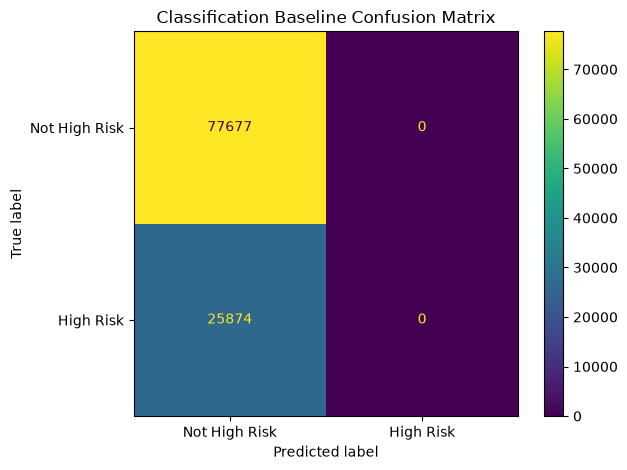

In [100]:
ConfusionMatrixDisplay(
    confusion_matrix=baseline_cm,
    display_labels=["Not High Risk", "High Risk"]
).plot()

plt.title("Classification Baseline Confusion Matrix")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "01_classification_baseline_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Classification Evaluation Focus

For the high-risk screening task, recall is especially important.

A false negative occurs when an observation is truly high risk but is
not flagged by the model. In a transportation-safety screening context,
this could cause a potentially important case to receive lower review
priority.

Accuracy is therefore interpreted together with precision, recall, and
F1 rather than used alone.

In [101]:
classification_baseline_results = pd.DataFrame({
    "Model": ["Majority-Class Baseline"],
    "Accuracy": [baseline_accuracy],
    "Precision": [baseline_precision],
    "Recall": [baseline_recall],
    "F1": [baseline_f1]
})

classification_baseline_results

,Model,Accuracy,Precision,Recall,F1
0,Majority-Class Baseline,0.750133,0.0,0.0,0.0


In [102]:
classification_baseline_results.to_csv(
    TABLE_DIR / "03_classification_baseline_results.csv",
    index=False
)

### Stage 4 Summary

A binary high-risk classification target was created using the 75th
percentile of the training-set accident-risk distribution.

The resulting high-risk threshold was 0.46. Using this cutoff,
approximately 25.3% of the training observations and 25.0% of the
validation observations were classified as high risk.

The majority-class baseline achieved an accuracy of 0.7501 by predicting
every validation observation as not high risk. However, its precision,
recall, and F1 score for the high-risk class were all 0.

The confusion matrix showed that all 25,874 high-risk validation
observations were missed by the baseline. This demonstrates why accuracy
alone is not sufficient for evaluating this screening task and why recall
is especially important for identifying high-risk cases.

The next stage will evaluate Logistic Regression to determine whether the
predictor variables can identify high-risk observations more effectively.

## Stage 5: Logistic Regression

This stage develops a Logistic Regression model to classify road
conditions as either high risk or not high risk.

The same preprocessing workflow from Stage 2 is combined with Logistic
Regression in a single pipeline.

Model performance is evaluated on the held-out validation set using
accuracy, precision, recall, F1 score, and the confusion matrix. Particular
attention is given to recall because missing a truly high-risk observation
would reduce the usefulness of the screening tool.

### Logistic Regression Pipeline

The preprocessing transformer and Logistic Regression classifier are
combined into a single pipeline so that the same transformation steps are
applied consistently during training and prediction.

In [103]:
classification_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000
            )
        )
    ]
)

### Model Training

The classification pipeline is fitted using the training predictors and
the binary high-risk labels created in Stage 4.

The validation set remains held out for model evaluation.

In [104]:
classification_pipeline.fit(
    X_train,
    y_train_high
);

### Validation Predictions

The fitted Logistic Regression model is used to predict whether each
validation observation should be classified as high risk or not high
risk.

In [105]:
classification_predictions = classification_pipeline.predict(X_val)

print(
    "Number of classification predictions:",
    len(classification_predictions)
)

print(
    "First 10 predicted classes:",
    classification_predictions[:10]
)

Number of classification predictions: 103551
First 10 predicted classes: [0 0 0 0 0 0 1 0 0 0]


### High-Risk Probabilities

In addition to binary class predictions, Logistic Regression produces an
estimated probability that each observation belongs to the high-risk
class.

These probabilities can later support risk ranking and prioritization,
rather than relying only on a yes-or-no classification.

In [106]:
high_risk_probabilities = classification_pipeline.predict_proba(X_val)[:, 1]

print(
    "First 10 high-risk probabilities:",
    high_risk_probabilities[:10]
)

print(
    "Minimum probability:",
    high_risk_probabilities.min()
)

print(
    "Maximum probability:",
    high_risk_probabilities.max()
)

First 10 high-risk probabilities: [1.71372899e-03 7.56047930e-03 1.35736023e-03 5.62667836e-03
 1.10362427e-02 2.52814979e-05 9.93835544e-01 1.30003375e-03
 6.91015065e-02 7.72463071e-03]
Minimum probability: 2.2318691379434112e-06
Maximum probability: 0.9999698639456046


### Classification Evaluation

The Logistic Regression model is evaluated using accuracy, precision,
recall, and F1 score.

Accuracy measures overall classification correctness. Precision measures
how often observations predicted as high risk are actually high risk.
Recall measures how many truly high-risk observations are successfully
identified. F1 balances precision and recall.

For this screening task, recall is particularly important because false
negatives represent high-risk observations that are not flagged for
additional review.

In [107]:
logistic_accuracy = accuracy_score(
    y_val_high,
    classification_predictions
)

logistic_precision = precision_score(
    y_val_high,
    classification_predictions,
    zero_division=0
)

logistic_recall = recall_score(
    y_val_high,
    classification_predictions,
    zero_division=0
)

logistic_f1 = f1_score(
    y_val_high,
    classification_predictions,
    zero_division=0
)

print(f"Logistic Regression Accuracy:  {logistic_accuracy:.4f}")
print(f"Logistic Regression Precision: {logistic_precision:.4f}")
print(f"Logistic Regression Recall:    {logistic_recall:.4f}")
print(f"Logistic Regression F1:        {logistic_f1:.4f}")

Logistic Regression Accuracy:  0.8961
Logistic Regression Precision: 0.8202
Logistic Regression Recall:    0.7483
Logistic Regression F1:        0.7826


### Logistic Regression Confusion Matrix

The confusion matrix is used to examine correct and incorrect
classification outcomes.

Of particular interest are false negatives, which represent actual
high-risk observations that the model fails to flag.

In [108]:
logistic_cm = confusion_matrix(
    y_val_high,
    classification_predictions
)

logistic_cm

array([[73434,  4243],
       [ 6513, 19361]])

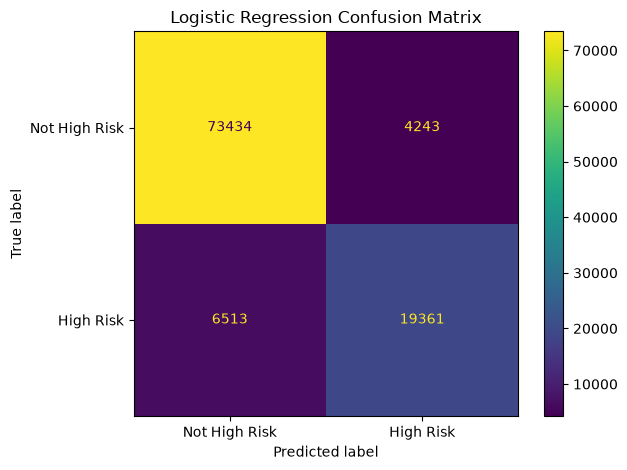

In [109]:
ConfusionMatrixDisplay(
    confusion_matrix=logistic_cm,
    display_labels=["Not High Risk", "High Risk"]
).plot()

plt.title("Logistic Regression Confusion Matrix")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "02_logistic_regression_confusion_matrix_050.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [110]:
tn, fp, fn, tp = logistic_cm.ravel()

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

True Negatives: 73434
False Positives: 4243
False Negatives: 6513
True Positives: 19361


### Baseline Comparison

Logistic Regression is compared with the majority-class baseline from
Stage 4 to determine whether the predictor variables improve high-risk
identification.

In [111]:
classification_results = pd.DataFrame({
    "Model": [
        "Majority-Class Baseline",
        "Logistic Regression"
    ],
    "Accuracy": [
        baseline_accuracy,
        logistic_accuracy
    ],
    "Precision": [
        baseline_precision,
        logistic_precision
    ],
    "Recall": [
        baseline_recall,
        logistic_recall
    ],
    "F1": [
        baseline_f1,
        logistic_f1
    ]
})

classification_results

,Model,Accuracy,Precision,Recall,F1
0,Majority-Class Baseline,0.750133,0.000000,0.00000,0.00000
1,Logistic Regression,0.896128,0.820242,0.74828,0.78261


In [112]:
classification_results.to_csv(
    TABLE_DIR / "04_classification_results_default_050.csv",
    index=False
)

### Training and Validation Performance

Training and validation classification performance are compared to check
whether the model performs consistently on seen and unseen observations.

In [113]:
train_classification_predictions = classification_pipeline.predict(
    X_train
)

train_accuracy = accuracy_score(
    y_train_high,
    train_classification_predictions
)

train_precision = precision_score(
    y_train_high,
    train_classification_predictions,
    zero_division=0
)

train_recall = recall_score(
    y_train_high,
    train_classification_predictions,
    zero_division=0
)

train_f1 = f1_score(
    y_train_high,
    train_classification_predictions,
    zero_division=0
)

classification_performance_comparison = pd.DataFrame({
    "Dataset": ["Training", "Validation"],
    "Accuracy": [
        train_accuracy,
        logistic_accuracy
    ],
    "Precision": [
        train_precision,
        logistic_precision
    ],
    "Recall": [
        train_recall,
        logistic_recall
    ],
    "F1": [
        train_f1,
        logistic_f1
    ]
})

classification_performance_comparison

,Dataset,Accuracy,Precision,Recall,F1
0,Training,0.894571,0.822316,0.744296,0.781363
1,Validation,0.896128,0.820242,0.748280,0.782610


In [114]:
classification_performance_comparison.to_csv(
    TABLE_DIR / "05_classification_train_validation_performance.csv",
    index=False
)

### Predicted High-Risk Rate

The proportion of validation observations flagged as high risk is
examined to understand how selective the Logistic Regression model is
relative to the observed high-risk rate.

In [115]:
actual_high_risk_rate = y_val_high.mean()
predicted_high_risk_rate = classification_predictions.mean()

print(
    f"Actual high-risk rate: {actual_high_risk_rate:.4f}"
)

print(
    f"Predicted high-risk rate: {predicted_high_risk_rate:.4f}"
)

Actual high-risk rate: 0.2499
Predicted high-risk rate: 0.2279


### Stage 5 Interpretation

Logistic Regression substantially outperformed the majority-class
baseline for identifying high-risk observations.

On the validation set, the model achieved an accuracy of 0.8961,
precision of 0.8202, recall of 0.7483, and an F1 score of 0.7826.
Unlike the baseline, which failed to identify any high-risk observations,
Logistic Regression successfully identified 19,361 of the 25,874 actual
high-risk validation cases.

The recall of 0.7483 indicates that approximately 74.8% of truly
high-risk observations were successfully flagged. However, 6,513
high-risk observations remained false negatives and were not identified
by the model. This is important for the proposed safety-screening use
case because missed high-risk cases may receive lower review priority.

Precision of 0.8202 indicates that approximately 82.0% of observations
flagged as high risk were actually high risk. The model therefore
maintains a relatively strong balance between identifying high-risk cases
and limiting unnecessary flags.

Training and validation performance were very similar across all
classification metrics, suggesting that the model generalizes
consistently to unseen observations and does not show clear evidence of
overfitting.

The model classified approximately 22.8% of validation observations as
high risk, compared with an actual high-risk rate of approximately
25.0%. This suggests that the default classification threshold produces
a somewhat conservative screening rule.

In addition to binary classifications, Logistic Regression provides
high-risk probabilities that can support ranking and prioritization of
observations for further transportation-safety review.

## Stage 6: Evaluation and Visualizations

This stage summarizes the performance of the regression and
classification models using visualizations and comparative metrics.

The regression model is evaluated using predicted versus actual accident
risk and residual behavior. The classification model is initially evaluated
using the default probability threshold of 0.50 through its confusion matrix,
performance metrics, and predicted high-risk probabilities. Threshold
optimization is performed in the following stage.

These results are interpreted in the context of the proposed
road-safety screening and prioritization use case.

### Actual vs Predicted Accident Risk

Actual validation accident-risk values are compared with the predictions
from Multiple Linear Regression.

Predictions closer to the diagonal reference line indicate better
agreement between predicted and observed accident risk.

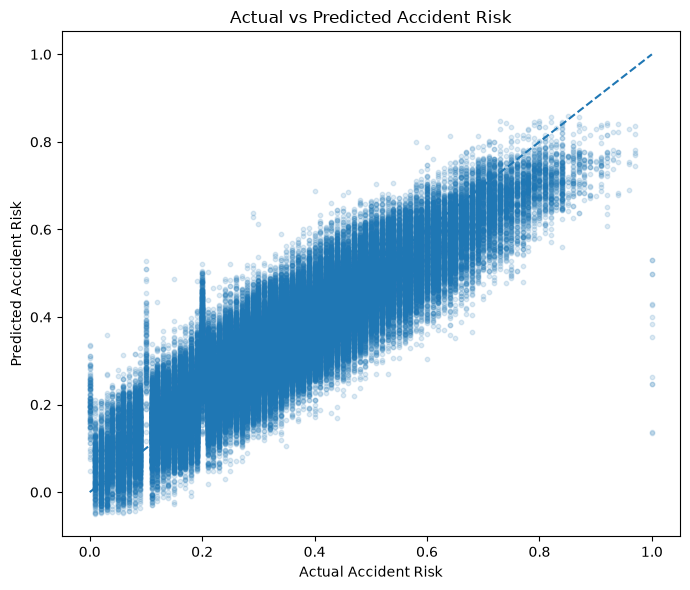

In [116]:
plt.figure(figsize=(7, 6))

plt.scatter(
    y_val,
    regression_predictions,
    alpha=0.15,
    s=10
)

plt.plot(
    [y_val.min(), y_val.max()],
    [y_val.min(), y_val.max()],
    linestyle="--"
)

plt.xlabel("Actual Accident Risk")
plt.ylabel("Predicted Accident Risk")
plt.title("Actual vs Predicted Accident Risk")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "03_actual_vs_predicted_accident_risk.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Regression Residuals

Residuals are calculated as the difference between the actual and
predicted accident-risk values.

A useful linear regression model should generally produce residuals
centered around zero without a strong systematic pattern.

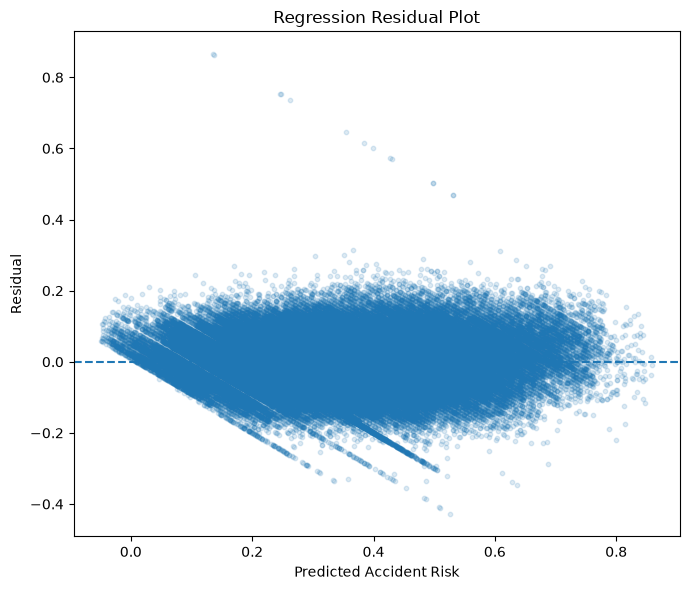

In [117]:
regression_residuals = y_val - regression_predictions

plt.figure(figsize=(7, 6))

plt.scatter(
    regression_predictions,
    regression_residuals,
    alpha=0.15,
    s=10
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Accident Risk")
plt.ylabel("Residual")
plt.title("Regression Residual Plot")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "04_regression_residuals.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Regression Performance Comparison

RMSE and MAE are compared between the mean baseline and Multiple Linear
Regression.

Lower values indicate smaller prediction errors.

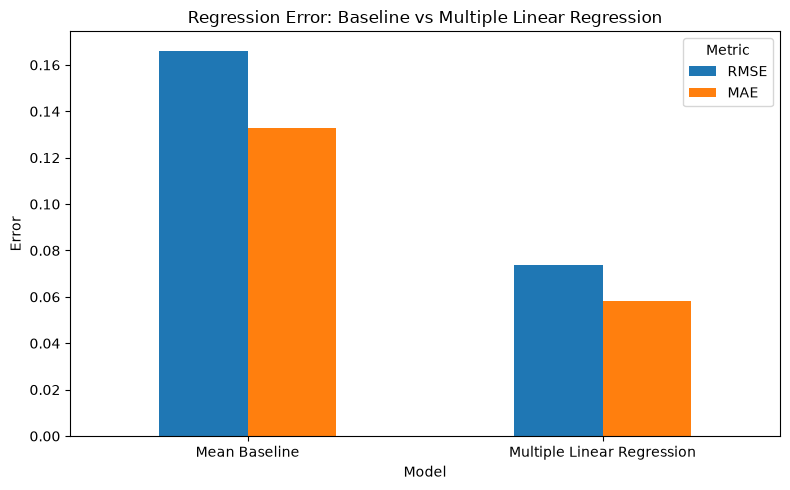

In [118]:
regression_error_plot = regression_results.set_index("Model")[
    ["RMSE", "MAE"]
]

regression_error_plot.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.ylabel("Error")
plt.title(
    "Regression Error: Baseline vs Multiple Linear Regression"
)
plt.xticks(rotation=0)
plt.legend(title="Metric")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "05_regression_error_baseline_vs_mlr.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### High-Risk Classification Results

The Logistic Regression confusion matrix shows that the model correctly
identified 19,361 high-risk validation observations while missing 6,513
high-risk cases.

The model also produced 4,243 false-positive high-risk flags.

### Classification Performance Comparison

Logistic Regression is compared with the majority-class baseline using
accuracy, precision, recall, and F1 score.

The comparison illustrates why overall accuracy alone is insufficient
for evaluating a high-risk screening model.

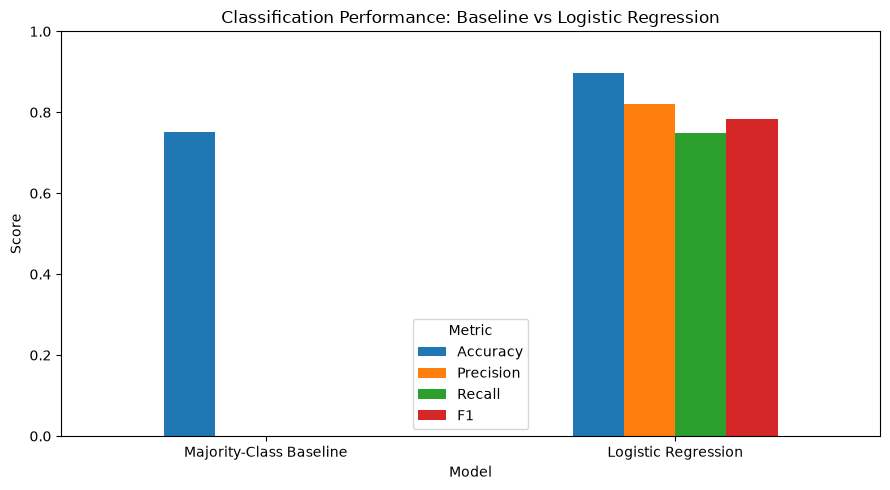

In [119]:
classification_plot = classification_results.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1"]
]

classification_plot.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.ylabel("Score")
plt.ylim(0, 1)
plt.title("Classification Performance: Baseline vs Logistic Regression")
plt.xticks(rotation=0)
plt.legend(title="Metric")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "06_classification_performance_default_050.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Predicted High-Risk Probability Distribution

The distribution of predicted high-risk probabilities is examined to
show how the Logistic Regression model separates lower-risk and
higher-risk observations.

These probabilities can be used to rank observations for review rather
than relying only on the default binary classification threshold.

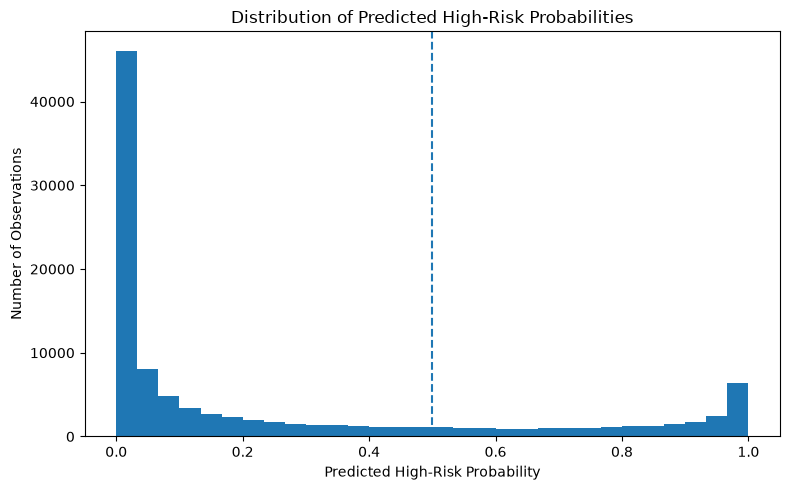

In [120]:
plt.figure(figsize=(8, 5))

plt.hist(
    high_risk_probabilities,
    bins=30
)

plt.axvline(
    x=0.5,
    linestyle="--"
)

plt.xlabel("Predicted High-Risk Probability")
plt.ylabel("Number of Observations")
plt.title("Distribution of Predicted High-Risk Probabilities")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "07_predicted_high_risk_probability_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### High-Risk Probability by Actual Class

Predicted probabilities are compared between observations that are
actually high risk and those that are not high risk.

Greater separation between the two distributions indicates that the
model can distinguish higher-risk observations from lower-risk
observations.

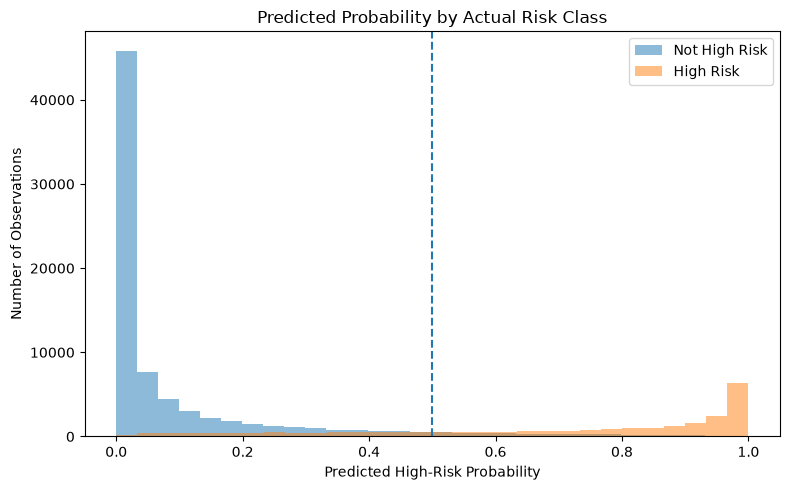

In [121]:
plt.figure(figsize=(8, 5))

plt.hist(
    high_risk_probabilities[y_val_high == 0],
    bins=30,
    alpha=0.5,
    label="Not High Risk"
)

plt.hist(
    high_risk_probabilities[y_val_high == 1],
    bins=30,
    alpha=0.5,
    label="High Risk"
)

plt.axvline(
    x=0.5,
    linestyle="--"
)

plt.xlabel("Predicted High-Risk Probability")
plt.ylabel("Number of Observations")
plt.title("Predicted Probability by Actual Risk Class")
plt.legend()

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "08_predicted_probability_by_actual_risk_class.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Model Performance Summary

The two modeling approaches serve complementary purposes.

Multiple Linear Regression estimates continuous accident risk, while
Logistic Regression identifies observations that should receive higher
priority for additional safety review.

In [122]:
model_summary = pd.DataFrame({
    "Model": [
        "Multiple Linear Regression",
        "Logistic Regression"
    ],
    "Primary Purpose": [
        "Estimate continuous accident risk",
        "Identify high-risk observations"
    ],
    "Key Validation Result": [
        f"R² = {regression_r2:.4f}",
        f"Recall = {logistic_recall:.4f}"
    ],
    "Additional Result": [
        f"RMSE = {regression_rmse:.4f}",
        f"F1 = {logistic_f1:.4f}"
    ]
})

model_summary

,Model,Primary Purpose,Key Validation Result,Additional Result
0,Multiple Linear Regression,Estimate continuous accident risk,R² = 0.8042,RMSE = 0.0735
1,Logistic Regression,Identify high-risk observations,Recall = 0.7483,F1 = 0.7826


In [123]:
model_summary.to_csv(
    TABLE_DIR / "06_model_performance_summary.csv",
    index=False
)

### Stage 6 Interpretation

The regression and classification results provide complementary evidence
that the available road, environmental, temporal, and historical
predictors contain useful information for accident-risk screening.

Multiple Linear Regression substantially improved upon the mean baseline.
On the validation set, the model achieved an RMSE of 0.0735, an MAE of
0.0583, and an R² of 0.8042. This indicates that the model explains
approximately 80.4% of the variation in accident risk in the held-out
validation data.

Logistic Regression also substantially outperformed the majority-class
baseline. **Using the default 0.50 probability threshold**, the classifier
achieved an accuracy of 0.8961, precision of 0.8202, recall of 0.7483,
and an F1 score of 0.7826. The model correctly identified 19,361 of the
25,874 actual high-risk validation observations.

For the proposed safety-screening application, recall is particularly
important because false negatives represent high-risk observations that
would not be flagged for additional review. At the default 0.50 threshold,
the model identified approximately 74.8% of high-risk cases, while 6,513
high-risk observations were still missed.

These results provide the baseline classification performance before
probability-threshold optimization. The following stage evaluates
alternative thresholds to determine whether recall and F1 performance
can be improved for the screening objective.

The predicted high-risk probabilities provide additional value beyond
binary classification. Rather than treating all flagged observations
equally, transportation analysts could use these probabilities to rank
observations and prioritize cases with higher estimated risk for further
investigation.

Overall, the results support the feasibility of the proposed proof-of-
concept screening approach. However, because the dataset is synthetic,
the models should not be interpreted as production-ready transportation
safety tools. Application to real transportation decisions would require
local crash and roadway data, additional validation, and review by
transportation-safety professionals.

## Stage 7: Classification Threshold Optimization

The default Logistic Regression classification threshold is 0.50.
However, the appropriate threshold depends on the screening objective.

Because this project emphasizes identifying high-risk observations,
recall is especially important. Lowering the probability threshold may
increase recall and reduce false negatives, although it may also increase
false positives and reduce precision.

This stage evaluates a range of classification probability thresholds to
examine the trade-off among accuracy, precision, recall, and F1 score.

In [124]:
threshold_results = []

thresholds = np.arange(
    0.20,
    0.81,
    0.01
)

for threshold in thresholds:

    threshold_predictions = (
        high_risk_probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val_high,
        threshold_predictions
    ).ravel()

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(
            y_val_high,
            threshold_predictions
        ),
        "Precision": precision_score(
            y_val_high,
            threshold_predictions
        ),
        "Recall": recall_score(
            y_val_high,
            threshold_predictions
        ),
        "F1": f1_score(
            y_val_high,
            threshold_predictions
        ),
        "False Positives": fp,
        "False Negatives": fn
    })

threshold_results_df = pd.DataFrame(
    threshold_results
)

threshold_results_df.head()

,Threshold,Accuracy,Precision,Recall,F1,False Positives,False Negatives
0,0.20,0.856235,0.651993,0.910760,0.759953,12578,2309
1,0.21,0.859856,0.659848,0.906354,0.763702,12089,2423
2,0.22,0.862773,0.666610,0.901832,0.766582,11670,2540
3,0.23,0.865767,0.673950,0.896498,0.769455,11222,2678
4,0.24,0.868104,0.680518,0.889928,0.771261,10810,2848


In [125]:
threshold_results_df.to_csv(
    TABLE_DIR / "07_classification_threshold_analysis.csv",
    index=False
)

In [126]:
best_f1_row = threshold_results_df.loc[
    threshold_results_df["F1"].idxmax()
]

best_f1_row

Threshold             0.400000
Accuracy              0.892459
Precision             0.773209
Recall                0.806021
F1                    0.789274
False Positives    6117.000000
False Negatives    5019.000000
Name: 20, dtype: float64

In [127]:
recall_candidates = (
    threshold_results_df[
        threshold_results_df["Recall"] >= 0.80
    ]
    .sort_values(
        "Threshold",
        ascending=False
    )
)

recall_candidates.head()

,Threshold,Accuracy,Precision,Recall,F1,False Positives,False Negatives
21,0.41,0.892903,0.777707,0.800070,0.788730,5917,5173
20,0.40,0.892459,0.773209,0.806021,0.789274,6117,5019
19,0.39,0.891522,0.767670,0.811432,0.788945,6354,4879
18,0.38,0.890740,0.762683,0.816920,0.788871,6577,4737
17,0.37,0.889581,0.756629,0.822718,0.788291,6847,4587


In [128]:
recall_candidates.to_csv(
    TABLE_DIR / "08_threshold_recall_candidates.csv",
    index=False
)

In [129]:
threshold_comparison = threshold_results_df[
    np.isclose(
        threshold_results_df["Threshold"],
        0.40
    )
    |
    np.isclose(
        threshold_results_df["Threshold"],
        0.50
    )
].copy()

threshold_comparison

,Threshold,Accuracy,Precision,Recall,F1,False Positives,False Negatives
20,0.4,0.892459,0.773209,0.806021,0.789274,6117,5019
30,0.5,0.896128,0.820242,0.748280,0.782610,4243,6513


In [130]:
threshold_comparison.to_csv(
    TABLE_DIR / "09_threshold_comparison_040_vs_050.csv",
    index=False
)

### Threshold Selection

Among the evaluated thresholds, 0.40 produced the highest validation F1
score.

Compared with the default 0.50 threshold, lowering the probability cutoff
to 0.40 increased recall from approximately 74.8% to 80.6% and reduced
false negatives from 6,513 to 5,019.

This improvement comes with a reduction in precision from approximately
82.0% to 77.3% and an increase in false positives.

Because the project is intended as a safety-screening tool, where missing
potentially high-risk observations is especially important, the 0.40
probability threshold was selected for the final modeling workflow.